# Thực thi Pohlig–Hellman trên smooth curve & so sánh chi phí

> **Topic 14 – ECC Cryptanalysis · Track A (generic ECDLP search)** <br>
> **Task:** *Thực thi PH trên smooth curve, so sánh chi phí (PH vs BSGS vs Pollard's rho)* <br>

### Quá trình
| Bước | Nội dung | Hàm chính |
|---|---|---|
| 0 | Môi trường, nạp lõi từ `gen_smooth_curves` / `toy_curve_gen` (import / fallback), công cụ đo | `measure`, `track_ecc_ops`, `get_cpu_freq_ghz` |
| 1 | Baby-step giant-step tổng quát (subroutine) + Pollard's rho (baseline generic thứ hai) | `bsgs_dlp`, `pollard_rho_dlp` |
| 2 | Định lý số dư Trung Hoa + thuật toán Pohlig–Hellman đầy đủ, kiểm tra trên ví dụ nhỏ (F_97) | `crt_combine`, `pohlig_hellman` |
| 3 | Đo chi phí PH vs BSGS vs Pollard's rho trên nhiều curve smooth (16–32 bit) và PH-only ở 40/48 bit | `benchmark_curve` |
| 4 | Ghi kết quả vào D2 (file theo curve + gộp vào `D2_ecdlp_benchmarks.csv`), vẽ biểu đồ đo thực tế vs ước lượng lý thuyết | `write_benchmark_csv`, `write_d2_csv`, `plot_benchmarks` |
| 5 | Selftest & CLI | `selftest`, `main` |

## Cơ sở lý thuyết
Cho $G$ sinh nhóm cyclic cấp $n=\prod_i q_i^{e_i}$ và $Q=dG$. Với mỗi thừa số $q_i^{e_i}$:

1. Chiếu xuống nhóm con cấp $q_i^{e_i}$: $G_i = \tfrac{n}{q_i^{e_i}}G$, $Q_i = \tfrac{n}{q_i^{e_i}}Q$ (vì $G_i$ có
   đúng bậc $q_i^{e_i}$ khi $G$ có đúng bậc $n$).
2. Giải $d_i \equiv d \pmod{q_i^{e_i}}$ bằng BSGS trong nhóm con nhỏ này — chi phí $O(\sqrt{q_i^{e_i}})$.
3. Ghép các $d_i$ lại bằng **CRT** (các $q_i^{e_i}$ nguyên tố cùng nhau từng đôi) để ra $d \bmod n$ duy nhất.

Tổng chi phí $\approx \sum_i e_i\sqrt{q_i}$ — đúng như `estimate_ph_cost` đã định nghĩa ở notebook trước. Ở đây ta
**cài đặt thật** thuật toán này và đo số phép nhóm + thời gian thực tế, rồi so với con số ước lượng đó.
Ngoài PH và BSGS toàn nhóm, notebook còn đo **Pollard's rho** (cũng $O(\sqrt{n})$ phép nhóm nhưng chỉ tốn $O(1)$ bộ nhớ) làm
baseline generic thứ hai. Mỗi thuật toán được đo trên cùng một cặp $(G, Q)$ với các đại lượng: số phép nhóm
(`group_ops`), số phép cộng/nhân đôi/nhân vô hướng thực tế (`track_ecc_ops`), thời gian wall/CPU, cycles và đỉnh RAM Python.

## Bước 0 – Môi trường và kế thừa lõi từ `gen_smooth_curves` / `toy_curve_gen`

**0a.** Tự dò thư mục gốc dự án (chứa `curves/`) bất kể mở notebook từ đâu, để các đường dẫn `data/` và `docs/charts/`
luôn đúng.

In [ ]:
import os, sys, platform, subprocess
from pathlib import Path

cwd = Path.cwd().resolve()
ROOT_DIR = next((p for p in [cwd, *cwd.parents] if (p / "curves").is_dir()), cwd)
for _p in (ROOT_DIR, ROOT_DIR / "curves", ROOT_DIR / "scripts"):
    if _p.is_dir() and str(_p) not in sys.path:
        sys.path.insert(0, str(_p))

DATA_DIR = ROOT_DIR / "data"
CHARTS_DIR = ROOT_DIR / "docs" / "charts"
print("ROOT_DIR =", ROOT_DIR)

**0b.** Nạp lõi số học: ưu tiên import từ `gen_smooth_curves.py`, nếu không có thì dùng bản sao tự chứa bên dưới.

In [ ]:
from __future__ import annotations
import argparse, csv, json, random, sys, time
from collections import Counter
from dataclasses import dataclass
from datetime import datetime, timezone
from math import gcd, isqrt, prod, sqrt
from pathlib import Path
from typing import Dict, List, Optional, Tuple

# Import các module cốt lõi từ curves/ và scripts/
from curves.ecc import ECC, Point, FindOrder
from curves.pohlig_hellman import Pohlig_hellman_ECC
from curves.bsgs import BSGS_ECC
from curves.pollard_rho import Pollard_Rho_ECC
from scripts.measure_harness import measure

try:
    from gen_smooth_curves import (
        Point, Curve, D1_COLUMNS, GENERATION_METHOD,
        is_prime, random_prime, factorize, sqrt_mod,
        count_points, count_points_naive, count_points_bsgs,
        classify, make_row, verify_row, write_csv, load_csv, parse_csv_row,
        generate_curve, estimate_bsgs_cost, estimate_ph_cost, ph_speedup,
        smoothness_profile, generate_smooth_curve_batch,
    )
    print("Đã import lõi từ gen_smooth_curves.py (cùng thư mục curves/).")
except ImportError:
    print("Không tìm thấy gen_smooth_curves.py -> dùng bản sao lõi số học nội bộ (tự chứa).")

    Point = Optional[Tuple[int, int]]
    GENERATION_METHOD = "test_pohlig_hellman.v1 (lõi kế thừa gen_smooth_curves.v1)"
    NAIVE_COUNT_LIMIT = 1 << 16

    D1_COLUMNS = [
        "curve_id", "p", "a", "b", "discriminant", "discriminant_ok",
        "E_count", "E_count_factorization", "base_point_x", "base_point_y",
        "subgroup_n", "n_bits", "n_factorization", "cofactor_h",
        "largest_prime_factor_n", "is_anomalous", "is_supersingular", "category",
        "source_for_point_class", "small_order_available", "generation_method",
        "seed", "notes", "git_commit", "created_at",
    ]
    _JSON_COLUMNS = {"E_count_factorization", "n_factorization", "small_order_available"}
    _BOOL_COLUMNS = {"discriminant_ok", "is_anomalous", "is_supersingular"}
    _INT_COLUMNS = {"n_bits", "seed"}

    _MR_BASES = (2, 3, 5, 7, 11, 13, 17, 19, 23, 29, 31, 37)

    def is_prime(n: int) -> bool:
        if n < 2:
            return False
        for q in _MR_BASES:
            if n % q == 0:
                return n == q
        d, s = n - 1, 0
        while d % 2 == 0:
            d //= 2; s += 1
        for a in _MR_BASES:
            x = pow(a, d, n)
            if x in (1, n - 1):
                continue
            for _ in range(s - 1):
                x = x * x % n
                if x == n - 1:
                    break
            else:
                return False
        return True

    def random_prime(rng: random.Random, bits: int) -> int:
        if bits < 8:
            raise ValueError("bits phải >= 8 cho toy curve")
        while True:
            cand = rng.getrandbits(bits) | (1 << (bits - 1)) | 1
            if is_prime(cand):
                return cand

    def _pollard_rho(n: int) -> int:
        rng = random.Random(n)
        while True:
            c = rng.randrange(1, n)
            x = y = rng.randrange(0, n)
            d = 1
            while d == 1:
                x = (x * x + c) % n
                y = (y * y + c) % n
                y = (y * y + c) % n
                d = gcd(abs(x - y), n)
            if d != n:
                return d

    def factorize(n: int) -> Dict[int, int]:
        if n < 1:
            raise ValueError("n phải >= 1")
        out: Dict[int, int] = {}
        d = 2
        while d < 5000 and d * d <= n:
            while n % d == 0:
                out[d] = out.get(d, 0) + 1
                n //= d
            d += 1 if d == 2 else 2

        def rec(m: int) -> None:
            if m == 1:
                return
            if is_prime(m):
                out[m] = out.get(m, 0) + 1
                return
            f = _pollard_rho(m)
            rec(f); rec(m // f)

        rec(n)
        return dict(sorted(out.items()))

    def sqrt_mod(n: int, p: int) -> Optional[int]:
        n %= p
        if n == 0:
            return 0
        if pow(n, (p - 1) // 2, p) != 1:
            return None
        if p % 4 == 3:
            return pow(n, (p + 1) // 4, p)
        q, s = p - 1, 0
        while q % 2 == 0:
            q //= 2; s += 1
        z = 2
        while pow(z, (p - 1) // 2, p) != p - 1:
            z += 1
        m, c, t, r = s, pow(z, q, p), pow(n, q, p), pow(n, (q + 1) // 2, p)
        while t != 1:
            i, t2 = 0, t
            while t2 != 1:
                t2 = t2 * t2 % p; i += 1
            b = pow(c, 1 << (m - i - 1), p)
            m, c = i, b * b % p
            t, r = t * c % p, r * b % p
        return r

    @dataclass(frozen=True)
    class Curve:
        p: int; a: int; b: int

        def discriminant(self) -> int:
            return (4 * pow(self.a, 3, self.p) + 27 * self.b * self.b) % self.p

        def is_nonsingular(self) -> bool:
            return self.discriminant() != 0

        def rhs(self, x: int) -> int:
            return (x * x * x + self.a * x + self.b) % self.p

        def contains(self, P: Point) -> bool:
            if P is None:
                return True
            x, y = P
            return 0 <= x < self.p and 0 <= y < self.p and (y * y - self.rhs(x)) % self.p == 0

        def neg(self, P: Point) -> Point:
            return None if P is None else (P[0], (-P[1]) % self.p)

        def add(self, P: Point, Q: Point) -> Point:
            if P is None:
                return Q
            if Q is None:
                return P
            p = self.p
            x1, y1 = P; x2, y2 = Q
            if x1 == x2:
                if (y1 + y2) % p == 0:
                    return None
                lam = (3 * x1 * x1 + self.a) * pow(2 * y1, -1, p) % p
            else:
                lam = (y2 - y1) * pow(x2 - x1, -1, p) % p
            x3 = (lam * lam - x1 - x2) % p
            return (x3, (lam * (x1 - x3) - y1) % p)

        def mul(self, k: int, P: Point) -> Point:
            if k < 0:
                return self.mul(-k, self.neg(P))
            R: Point = None
            while k:
                if k & 1:
                    R = self.add(R, P)
                P = self.add(P, P)
                k >>= 1
            return R

        def random_point(self, rng: random.Random) -> Tuple[int, int]:
            while True:
                x = rng.randrange(self.p)
                y = sqrt_mod(self.rhs(x), self.p)
                if y is not None:
                    return (x, y if rng.getrandbits(1) else (-y) % self.p)

        def point_order(self, P: Point, group_order: int, factors: Dict[int, int]) -> int:
            order = group_order
            for q in factors:
                while order % q == 0 and self.mul(order // q, P) is None:
                    order //= q
            return order

        @staticmethod
        def from_row(row: dict) -> "Curve":
            return Curve(int(row["p"]), int(row["a"]), int(row["b"]))

        @staticmethod
        def base_point_from_row(row: dict) -> Tuple[int, int]:
            return (int(row["base_point_x"]), int(row["base_point_y"]))

    def count_points_naive(E: Curve) -> int:
        sq = Counter(y * y % E.p for y in range(E.p))
        return 1 + sum(sq.get(E.rhs(x), 0) for x in range(E.p))

    def _hasse_candidates(E: Curve, P, lo: int, hi: int) -> List[int]:
        m = isqrt(hi - lo + 1) + 1
        baby: Dict[Point, List[int]] = {}
        R: Point = None
        for j in range(m):
            baby.setdefault(R, []).append(j)
            R = E.add(R, P)
        giant_step = E.neg(R)
        T = E.neg(E.mul(lo, P))
        found: List[int] = []
        for i in range(m):
            for j in baby.get(T, ()):
                N = lo + i * m + j
                if N <= hi:
                    found.append(N)
            T = E.add(T, giant_step)
        return found

    def count_points_bsgs(E: Curve, rng: Optional[random.Random] = None, max_points: int = 40) -> int:
        rng = rng or random.Random(E.p)
        w = 2 * isqrt(E.p) + 2
        lo, hi = E.p + 1 - w, E.p + 1 + w
        cands: Optional[List[int]] = None
        for _ in range(max_points):
            P = E.random_point(rng)
            if cands is None:
                c = _hasse_candidates(E, P, lo, hi)
                if len(c) > 10000:
                    continue
                cands = c
            else:
                cands = [N for N in cands if E.mul(N, P) is None]
            if len(cands) == 1:
                return cands[0]
            if not cands:
                raise RuntimeError("count_points_bsgs: không còn ứng viên")
        raise RuntimeError("count_points_bsgs: không xác định được duy nhất #E")

    def count_points(E: Curve, rng: Optional[random.Random] = None) -> int:
        return count_points_naive(E) if E.p < NAIVE_COUNT_LIMIT else count_points_bsgs(E, rng)

    def _fact_list(f: Dict[int, int]) -> List[dict]:
        return [{"prime": str(q), "exponent": e} for q, e in f.items()]

    def classify(p: int, N: int, n: int, h: int, fn: Dict[int, int], smooth_bound: Optional[int]) -> str:
        if N == p:
            return "anomalous"
        if N == p + 1:
            return "supersingular"
        n_prime = len(fn) == 1 and next(iter(fn.values())) == 1
        if n_prime and h == 1:
            return "safe_prime_order"
        if n_prime and h > 1:
            return "cofactor_gt1"
        if smooth_bound is not None and max(fn) <= smooth_bound:
            return "smooth_order"
        return "smooth_order" if max(fn) < 1 << 20 else "cofactor_gt1"

    def _utc_now() -> str:
        return datetime.now(timezone.utc).strftime("%Y-%m-%dT%H:%M:%SZ")

    def git_commit() -> str:
        try:
            import subprocess
            return subprocess.check_output(["git", "rev-parse", "--short", "HEAD"],
                                            stderr=subprocess.DEVNULL).decode().strip()
        except Exception:
            return "0000000"

    def make_row(E: Curve, G, N: int, fN: Dict[int, int], n: int, fn: Dict[int, int],
                 seed: int, curve_id: str, smooth_bound: Optional[int] = None,
                 notes: Optional[str] = None, commit: Optional[str] = None) -> dict:
        h = N // n
        disc = E.discriminant()
        return {
            "curve_id": curve_id, "p": str(E.p), "a": str(E.a), "b": str(E.b),
            "discriminant": str(disc), "discriminant_ok": disc != 0,
            "E_count": str(N), "E_count_factorization": _fact_list(fN),
            "base_point_x": str(G[0]), "base_point_y": str(G[1]),
            "subgroup_n": str(n), "n_bits": n.bit_length(),
            "n_factorization": _fact_list(fn),
            "cofactor_h": str(h), "largest_prime_factor_n": str(max(fn)),
            "is_anomalous": N == E.p, "is_supersingular": N == E.p + 1,
            "category": classify(E.p, N, n, h, fn, smooth_bound),
            "source_for_point_class": None, "small_order_available": None,
            "generation_method": GENERATION_METHOD, "seed": seed,
            "notes": notes, "git_commit": commit or git_commit(), "created_at": _utc_now(),
        }

    MODES = ("prime", "cofactor", "smooth")

    def generate_curve(n_bits: int, mode: str = "prime", seed: int = 0, max_cofactor: int = 16,
                        smooth_bound: Optional[int] = None, allow_special: bool = False,
                        max_tries: int = 200000, curve_id: Optional[str] = None) -> dict:
        if mode not in MODES:
            raise ValueError(f"mode phải thuộc {MODES}")
        if n_bits < 8:
            raise ValueError("n_bits phải >= 8")
        if mode == "smooth" and smooth_bound is None:
            smooth_bound = 1 << max(4, n_bits // 3)
        rng = random.Random(seed)
        cid = curve_id or f"crv-{seed & 0xFFFFFFFF:08x}"

        for _ in range(max_tries):
            p_bits = n_bits + rng.randint(1, max(1, max_cofactor.bit_length() - 1)) if mode == "cofactor" else n_bits
            p = random_prime(rng, p_bits)
            E = Curve(p, rng.randrange(p), rng.randrange(p))
            if not E.is_nonsingular():
                continue
            try:
                N = count_points(E, rng)
            except RuntimeError:
                continue
            if (N == p or N == p + 1) and not allow_special:
                continue
            fN = factorize(N)
            qmax = max(fN)

            if mode == "prime":
                if len(fN) != 1 or fN[qmax] != 1 or N.bit_length() != n_bits:
                    continue
                n, fn, G = N, fN, E.random_point(rng)
            elif mode == "cofactor":
                h = N // qmax
                if not (fN[qmax] == 1 and 2 <= h <= max_cofactor and qmax.bit_length() == n_bits):
                    continue
                n, fn = qmax, {qmax: 1}
                P = E.random_point(rng)
                G = E.mul(h, P)
                if G is None:
                    continue
            else:  # smooth
                if qmax > smooth_bound or N.bit_length() < n_bits:
                    continue
                best, best_n = None, 0
                for _t in range(20):
                    P = E.random_point(rng)
                    o = E.point_order(P, N, fN)
                    if o > best_n:
                        best, best_n = P, o
                n = best_n
                if n.bit_length() != n_bits or len(factorize(n)) < 2:
                    continue
                fn, G = factorize(n), best
            return make_row(E, G, N, fN, n, fn, seed, cid, smooth_bound=smooth_bound, notes=f"mode={mode}")
        raise RuntimeError(f"Không sinh được curve (n_bits={n_bits}, mode={mode}) sau {max_tries} lần thử")

    def _to_cell(col: str, v):
        if v is None:
            return ""
        if col in _JSON_COLUMNS:
            return json.dumps(v, separators=(",", ":"))
        if col in _BOOL_COLUMNS:
            return "true" if v else "false"
        return str(v)

    def parse_csv_row(raw: dict) -> dict:
        row: dict = {}
        for col in D1_COLUMNS:
            v = raw.get(col, "")
            if col in _JSON_COLUMNS:
                row[col] = json.loads(v) if v else None
            elif col in _BOOL_COLUMNS:
                row[col] = v.strip().lower() == "true"
            elif col in _INT_COLUMNS:
                row[col] = int(v)
            else:
                row[col] = v if v != "" else None
        return row

    def write_csv(rows: List[dict], path: str, append: bool = False) -> None:
        path_ = Path(path)
        path_.parent.mkdir(parents=True, exist_ok=True)
        exists = append and path_.exists() and path_.stat().st_size > 0
        with open(path_, "a" if exists else "w", newline="", encoding="utf-8") as f:
            w = csv.writer(f)
            if not exists:
                w.writerow(D1_COLUMNS)
            for r in rows:
                w.writerow([_to_cell(c, r.get(c)) for c in D1_COLUMNS])

    def load_csv(path: str) -> List[dict]:
        with open(path, newline="", encoding="utf-8") as f:
            return [parse_csv_row(r) for r in csv.DictReader(f)]

    def verify_row(row: dict, recount: bool = True) -> List[str]:
        row = parse_csv_row(row) if isinstance(row.get("discriminant_ok"), str) else row
        errs: List[str] = []
        p, a, b = int(row["p"]), int(row["a"]), int(row["b"])
        E = Curve(p, a, b)
        N, n, h = int(row["E_count"]), int(row["subgroup_n"]), int(row["cofactor_h"])
        G = Curve.base_point_from_row(row)
        if not is_prime(p) or p <= 3:
            errs.append("p không phải số nguyên tố > 3")
        if not E.is_nonsingular() or str(E.discriminant()) != str(row["discriminant"]):
            errs.append("discriminant sai hoặc curve suy biến")
        if not E.contains(G):
            errs.append("G không nằm trên curve")
        if E.mul(n, G) is not None:
            errs.append("n*G != O")
        fn = {int(f["prime"]): f["exponent"] for f in row["n_factorization"]}
        fN = {int(f["prime"]): f["exponent"] for f in row["E_count_factorization"]}
        for q in fn:
            if not is_prime(q):
                errs.append(f"thừa số {q} của n không nguyên tố")
            elif E.mul(n // q, G) is None:
                errs.append(f"bậc của G nhỏ hơn n (chia hết cho {q} lần nữa)")
        if prod(q ** e for q, e in fn.items()) != n:
            errs.append("n_factorization không nhân lại ra n")
        if prod(q ** e for q, e in fN.items()) != N:
            errs.append("E_count_factorization không nhân lại ra #E")
        if n * h != N:
            errs.append("n * h != #E")
        if n.bit_length() != int(row["n_bits"]):
            errs.append("n_bits sai")
        if str(max(fn)) != str(row["largest_prime_factor_n"]):
            errs.append("largest_prime_factor_n sai")
        if bool(row["is_anomalous"]) != (N == p) or bool(row["is_supersingular"]) != (N == p + 1):
            errs.append("cờ anomalous/supersingular sai")
        if abs(N - (p + 1)) > 2 * isqrt(p) + 2:
            errs.append("#E vi phạm cận Hasse")
        if recount and count_points(E) != N:
            errs.append("đếm lại #E không khớp")
        return errs

    def estimate_bsgs_cost(n: int) -> float:
        return sqrt(n)

    def estimate_ph_cost(fn: Dict[int, int]) -> float:
        return sum(e * sqrt(q) for q, e in fn.items())

    def ph_speedup(fn: Dict[int, int]) -> float:
        n = prod(q ** e for q, e in fn.items())
        return estimate_bsgs_cost(n) / estimate_ph_cost(fn)

    def smoothness_profile(row: dict) -> dict:
        fn = {int(f["prime"]): f["exponent"] for f in row["n_factorization"]}
        n = prod(q ** e for q, e in fn.items())
        qmax = max(fn)
        return {
            "curve_id": row["curve_id"], "n_bits": row["n_bits"], "n": n,
            "largest_prime_factor": qmax, "num_distinct_primes": len(fn),
            "estimated_bsgs_cost": estimate_bsgs_cost(n),
            "estimated_ph_cost": estimate_ph_cost(fn),
            "ph_speedup": ph_speedup(fn), "category": row["category"],
        }

    def generate_smooth_curve_batch(bit_list, bound_list, seed: int = 14, per_combo: int = 1,
                                    allow_special: bool = False, max_tries: int = 200000):
        rows, analysis, idx = [], [], 0
        for n_bits in bit_list:
            for B in bound_list:
                if B < (1 << 4):
                    continue
                for _ in range(per_combo):
                    s = seed * 1_000_003 + idx
                    try:
                        row = generate_curve(n_bits, mode="smooth", seed=s, smooth_bound=B,
                                             allow_special=allow_special, max_tries=max_tries,
                                             curve_id=f"crv-sm-{idx:08x}")
                    except RuntimeError as e:
                        print(f"  bỏ qua (n_bits={n_bits}, B={B}): {e}")
                        idx += 1
                        continue
                    rows.append(row)
                    analysis.append(smoothness_profile(row) | {"smooth_bound": B})
                    idx += 1
        return rows, analysis

print("Sẵn sàng: Curve, generate_curve, generate_smooth_curve_batch, estimate_*_cost đã có trong scope.")

Đã import lõi số học từ toy_curve_gen.py (cùng thư mục curves/).
Sẵn sàng: Curve, generate_curve, verify_row, write_csv/load_csv đã có trong scope.
Không tìm thấy gen_smooth_curves.py -> dùng bản sao lõi số học nội bộ (tự chứa).
Sẵn sàng: Curve, generate_curve, generate_smooth_curve_batch, estimate_*_cost đã có trong scope.


**0c.** Công cụ đo dùng chung:
- `measure(fn, repeat, warmup, memory)` – thời gian wall/CPU (trung vị) và đỉnh RAM; ưu tiên `scripts/measure_harness.py`
  của dự án, nếu không có thì dùng bản dự phòng (`perf_counter_ns` + `tracemalloc`).
- `track_ecc_ops()` – đếm số phép **cộng / nhân đôi / nhân vô hướng** thật sự mà `Curve` thực hiện (vá tạm `Curve.add`/`Curve.mul`).
- `get_cpu_freq_ghz()` – quy đổi `cpu_time_ns` → cycles khi chưa có RDTSC.

In [4]:
import tracemalloc, statistics
from contextlib import contextmanager

try:
    from scripts.measure_harness import measure
    print("Dùng measure() từ scripts/measure_harness.py")
except ImportError:
    print("Không tìm thấy scripts/measure_harness.py -> dùng measure() dự phòng (perf_counter_ns + tracemalloc).")

    def measure(fn, repeat: int = 3, warmup: int = 1, memory: bool = True) -> dict:
        for _ in range(warmup):
            fn()
        walls, cpus, result = [], [], None
        for _ in range(repeat):
            w0, c0 = time.perf_counter_ns(), time.process_time_ns()
            result = fn()
            cpus.append(time.process_time_ns() - c0)
            walls.append(time.perf_counter_ns() - w0)
        peak = None
        if memory:
            tracemalloc.start()
            fn()
            _, peak = tracemalloc.get_traced_memory()
            tracemalloc.stop()
        return {
            "result": result,
            "wall_time_ns": int(statistics.median(walls)),
            "cpu_time_ns": int(statistics.median(cpus)),
            "cpu_cycles": None,
            "memory_peak_kib": None if peak is None else peak / 1024,
            "rss_peak_kib": None,
        }


# ---- đếm phép toán điểm thật sự --------------------------------------------------
@dataclass
class ECCOpsCounter:
    add_ops: int = 0
    double_ops: int = 0
    mul_ops: int = 0

    @property
    def total_ops(self) -> int:
        return self.add_ops + self.double_ops + self.mul_ops


@contextmanager
def track_ecc_ops():
    """Tạm thời đếm số phép cộng điểm, nhân đôi điểm và nhân vô hướng của Curve."""
    counter = ECCOpsCounter()
    orig_add, orig_mul = Curve.add, Curve.mul

    def counted_add(self, P, Q):
        if P is not None and Q is not None:
            if P == Q:
                counter.double_ops += 1
            else:
                counter.add_ops += 1
        return orig_add(self, P, Q)

    def counted_mul(self, k, P):
        counter.mul_ops += 1
        return orig_mul(self, k, P)

    Curve.add, Curve.mul = counted_add, counted_mul
    try:
        yield counter
    finally:
        Curve.add, Curve.mul = orig_add, orig_mul


def get_cpu_freq_ghz() -> float:
    """Lấy xung nhịp CPU (GHz) để quy đổi cpu_time_ns -> cycles nếu chưa dùng RDTSC."""
    try:
        import psutil
        freq = psutil.cpu_freq()
        if freq and freq.current > 0:
            return freq.current / 1000.0
    except ImportError:
        pass
    try:
        if platform.system() == "Linux":
            with open("/proc/cpuinfo") as f:
                for line in f:
                    if "cpu MHz" in line:
                        return float(line.split(":")[1].strip()) / 1000.0
        elif platform.system() == "Windows":
            out = subprocess.check_output(["wmic", "cpu", "get", "MaxClockSpeed"], text=True)
            mhz = [int(s) for s in out.split() if s.isdigit()]
            if mhz:
                return mhz[0] / 1000.0
    except Exception:
        pass
    return 2.5


CPU_GHZ = get_cpu_freq_ghz()
print(f"Sẵn sàng: measure, track_ecc_ops, get_cpu_freq_ghz (CPU ≈ {CPU_GHZ:.2f} GHz)")

Không tìm thấy scripts/measure_harness.py -> dùng measure() dự phòng (perf_counter_ns + tracemalloc).
Sẵn sàng: measure, track_ecc_ops, get_cpu_freq_ghz (CPU ≈ 3.69 GHz)


## Bước 1 – `bsgs_dlp`: baby-step giant-step tổng quát (subroutine)

Giải $k$ sao cho $kP=Q$, biết $P$ có đúng bậc `order`. Đây là subroutine dùng **hai lần**:
- Làm baseline "BSGS toàn nhóm" (không khai thác smoothness, `order = n`).
- Làm lõi giải DLP trong từng nhóm con cấp $q_i^{e_i}$ bên trong `pohlig_hellman`.

`op_counter["group_ops"]` đếm đúng số phép cộng nhóm ở baby-step + giant-step — đây là đại lượng khớp với công thức
lý thuyết $O(\sqrt{\text{order}})$ đã dùng ở `estimate_bsgs_cost`/`estimate_ph_cost` (không tính 1-2 phép nhân vô
hướng rẻ $O(\log n)$ dùng để chiếu xuống nhóm con).

In [7]:
def bsgs_dlp(E: Curve, P: Tuple[int, int], Q: Point, order: int,
             op_counter: Optional[Dict[str, int]] = None) -> Optional[int]:
    """Giải k trong [0, order) sao cho k*P = Q, biết P có đúng bậc `order`."""
    if op_counter is None:
        op_counter = {"group_ops": 0}
    if Q is None:
        return 0
    m = isqrt(order - 1) + 1
    baby: Dict[Point, int] = {}
    R: Point = None
    for j in range(m):
        baby.setdefault(R, j)
        R = E.add(R, P); op_counter["group_ops"] += 1
    giant_step = E.neg(E.mul(m, P))  # 1 phép nhân vô hướng, O(log m) -- không tính vào group_ops
    T = Q
    for i in range(m):
        if T in baby:
            k = i * m + baby[T]
            if k < order and E.mul(k, P) == Q:
                return k
        T = E.add(T, giant_step); op_counter["group_ops"] += 1
    return None

In [8]:
# Chạy thử: lại đúng ví dụ E: y^2 = x^3 + 2x + 3 trên F_97, P = (3, 6) từ toy_curve_gen
E97 = Curve(97, 2, 3)
P97 = (3, 6)
k, R = 1, P97
while R is not None:
    R, k = E97.add(R, P97), k + 1
order_P97 = k
print("bậc của P =", order_P97)

d_true = 11 % order_P97 or 1
Q97 = E97.mul(d_true, P97)
op = {"group_ops": 0}
d_bsgs = bsgs_dlp(E97, P97, Q97, order_P97, op_counter=op)
print(f"d thật={d_true} | bsgs_dlp tìm được={d_bsgs} | khớp={d_bsgs == d_true} | group_ops={op['group_ops']}")

bậc của P = 5
d thật=1 | bsgs_dlp tìm được=1 | khớp=True | group_ops=3


### 1b. `pollard_rho_dlp`: Pollard's rho (baseline generic thứ hai)

Đi bộ ngẫu nhiên tất định trên nhóm: mỗi trạng thái là $X = aP + bQ$, chia nhóm thành 3 phần theo $x \bmod 3$ và dùng
$X \mapsto X+P$ / $X+Q$ / $2X$. Dò chu trình bằng Floyd; khi hai trạng thái va chạm $a_1P+b_1Q = a_2P+b_2Q$ ta có
$(a_1-a_2)P=(b_2-b_1)Q$ nên $d\,(b_2-b_1)\equiv a_1-a_2 \pmod{\text{order}}$. Khi $\gcd(b_2-b_1,\text{order})>1$
(order hợp số, đúng trường hợp smooth) ta thử $\gcd$ ứng viên rồi kiểm lại bằng $kP=Q$; thất bại thì khởi động lại với
điểm đầu khác (`seed` cố định để tái lập).

`group_ops` đếm mỗi bước của dãy (kể cả 2 bước/vòng của con trỏ nhanh Floyd); chi phí khởi tạo $aP+bQ$ không tính — cùng
quy ước với `bsgs_dlp`.

In [9]:
def pollard_rho_dlp(E: Curve, P: Tuple[int, int], Q: Point, order: int,
                    op_counter: Optional[Dict[str, int]] = None,
                    seed: int = 0, max_restarts: int = 64) -> Optional[int]:
    """Giải k trong [0, order) sao cho k*P = Q (P có đúng bậc `order`) bằng Pollard's rho + Floyd."""
    if op_counter is None:
        op_counter = {"group_ops": 0}
    if Q is None:
        return 0
    rng = random.Random(seed)

    def step(X, a, b):
        op_counter["group_ops"] += 1
        part = 0 if X is None else X[0] % 3
        if part == 0:
            return E.add(X, P), (a + 1) % order, b
        if part == 1:
            return E.add(X, Q), a, (b + 1) % order
        return E.add(X, X), (2 * a) % order, (2 * b) % order

    limit = 20 * isqrt(order) + 1000
    for _ in range(max_restarts):
        a0, b0 = rng.randrange(order), rng.randrange(order)
        X0 = E.add(E.mul(a0, P), E.mul(b0, Q))
        T, aT, bT = X0, a0, b0
        H, aH, bH = X0, a0, b0
        met = False
        for _ in range(limit):
            T, aT, bT = step(T, aT, bT)
            H, aH, bH = step(H, aH, bH)
            H, aH, bH = step(H, aH, bH)
            if T == H:
                met = True
                break
        if not met:
            continue
        da, db = (aT - aH) % order, (bH - bT) % order   # d * db ≡ da (mod order)
        g = gcd(db, order)
        if db == 0 or da % g:
            continue
        og = order // g
        d0 = (da // g) * pow(db // g, -1, og) % og if og > 1 else 0
        for i in range(g):
            k = d0 + i * og
            if E.mul(k, P) == Q:
                return k
    return None

In [10]:
# Chạy thử trên đúng ví dụ F_97 (điểm bậc nhỏ) và trên một nhóm lớn hơn
ok_rho = True
for d in range(order_P97):
    Qd = E97.mul(d, P97)
    ok_rho &= (pollard_rho_dlp(E97, P97, Qd, order_P97) == d)
print("rho đúng với mọi d trong nhóm bậc", order_P97, "trên F_97:", ok_rho)

row16 = generate_curve(16, mode="smooth", seed=7)
E16, G16, n16 = Curve.from_row(row16), Curve.base_point_from_row(row16), int(row16["subgroup_n"])
d16 = 12345 % n16
op_r = {"group_ops": 0}
d_rho = pollard_rho_dlp(E16, G16, E16.mul(d16, G16), n16, op_counter=op_r)
print(f"n={n16} ({n16.bit_length()} bit) | d thật={d16} | rho tìm được={d_rho} | khớp={d_rho == d16} | "
      f"group_ops={op_r['group_ops']} (≈ {op_r['group_ops'] / sqrt(n16):.1f}·√n)")

rho đúng với mọi d trong nhóm bậc 5 trên F_97: True
n=38019 (16 bit) | d thật=12345 | rho tìm được=12345 | khớp=True | group_ops=906 (≈ 4.6·√n)


## Bước 2 – `crt_combine` (CRT) và `pohlig_hellman`

`crt_combine` ghép tuần tự từng cặp $(r_i \bmod m_i)$ bằng công thức Garner cổ điển, dùng `pow(M, -1, m)` (nghịch
đảo modulo, có sẵn từ Python 3.8). Các $m_i = q_i^{e_i}$ ở đây **luôn nguyên tố cùng nhau từng đôi** vì $q_i$ là các
thừa số nguyên tố phân biệt trong phân tích của $n$.

`pohlig_hellman` lặp qua từng thừa số nguyên tố của $n$, chiếu $G,Q$ xuống nhóm con tương ứng, gọi `bsgs_dlp` để
giải $d \bmod q_i^{e_i}$, rồi ghép lại bằng CRT.

In [11]:
def crt_combine(remainders: List[int], moduli: List[int]) -> Tuple[int, int]:
    """Ghép (r_i mod m_i) -> (x mod M) với M = prod(m_i), các m_i nguyên tố cùng nhau từng đôi."""
    x, M = remainders[0] % moduli[0], moduli[0]
    for r, m in zip(remainders[1:], moduli[1:]):
        if gcd(M, m) != 1:
            raise ValueError("CRT: các modulus phải nguyên tố cùng nhau")
        k = (r - x) * pow(M, -1, m) % m
        x = x + M * k
        M *= m
    return x % M, M


def pohlig_hellman(E: Curve, G: Tuple[int, int], Q: Point, n: int, factors: Dict[int, int],
                   op_counter: Optional[Dict[str, int]] = None) -> int:
    """Giải d sao cho d*G = Q, biết G có đúng bậc n và factors = phân tích thừa số của n."""
    if op_counter is None:
        op_counter = {"group_ops": 0}
    remainders, moduli = [], []
    for q, e in sorted(factors.items()):
        qe = q ** e
        cofactor = n // qe
        Gi = E.mul(cofactor, G)
        Qi = E.mul(cofactor, Q)
        di = bsgs_dlp(E, Gi, Qi, qe, op_counter=op_counter)
        if di is None:
            raise RuntimeError(f"Không giải được DLP trong nhóm con bậc {qe} (q={q}, e={e})")
        remainders.append(di); moduli.append(qe)
    d, M = crt_combine(remainders, moduli)
    assert M == n, "Tích các q_i^e_i phải bằng n (factors phải là phân tích đầy đủ của n)"
    return d % n

In [12]:
# Chạy thử: PH trên đúng ví dụ F_97 ở trên, factorize bậc của P rồi so với bsgs_dlp vừa chạy
fP97 = factorize(order_P97)
print("phân tích bậc của P:", fP97)
op_ph97 = {"group_ops": 0}
d_ph97 = pohlig_hellman(E97, P97, Q97, order_P97, fP97, op_counter=op_ph97)
print(f"d thật={d_true} | pohlig_hellman tìm được={d_ph97} | khớp={d_ph97 == d_true} | "
      f"group_ops={op_ph97['group_ops']} (so với bsgs_dlp toàn nhóm: {op['group_ops']})")

phân tích bậc của P: {5: 1}
d thật=1 | pohlig_hellman tìm được=1 | khớp=True | group_ops=3 (so với bsgs_dlp toàn nhóm: 3)


## Bước 3 – Đo chi phí: Pohlig–Hellman vs BSGS toàn nhóm vs Pollard's rho

`benchmark_curve(row, seed)` trên một bản ghi D1 (`category="smooth_order"`):
1. Sinh khoá bí mật ngẫu nhiên $d$, công khai $Q=dG$.
2. Giải lại $d$ bằng **BSGS toàn nhóm** (`bsgs_dlp(E, G, Q, n)`, không khai thác smoothness) — baseline 1.
3. Giải lại $d$ bằng **Pollard's rho** (`pollard_rho_dlp`) — baseline 2.
4. Giải lại $d$ bằng **Pohlig–Hellman** (`pohlig_hellman(E, G, Q, n, n_factorization)`) — khai thác smoothness.
5. Với mỗi thuật toán ghi lại: `group_ops` (khớp công thức lý thuyết), số phép cộng/nhân đôi/nhân vô hướng thật
   (`track_ecc_ops`), thời gian wall/CPU (trung vị của vài lần lặp sau 1 lần warmup), cycles và đỉnh RAM.
6. So `group_ops` đo được với `estimate_bsgs_cost` / `estimate_ph_cost` (lý thuyết).

BSGS và rho chỉ chạy khi `n` không quá `max_generic_bits` (mặc định 32 bit) để tránh treo máy; ở các curve lớn hơn chỉ PH.

In [13]:
ALGO_LABELS = {"Pohlig_Hellman": "Pohlig-Hellman", "BSGS": "BSGS", "Pollard_Rho": "Pollard's rho"}


def _fact_str(fn: Dict[int, int]) -> str:
    return " * ".join(f"{q}^{e}" if e > 1 else f"{q}" for q, e in sorted(fn.items()))


def _run_algo(run, d_true: int, repeat: int) -> dict:
    """run(op_counter) -> d. Trả về toàn bộ số liệu đo của một thuật toán trên một bài toán."""
    oc = {"group_ops": 0}
    with track_ecc_ops() as ops:                      # 1 lần chạy riêng để đếm phép toán
        d_found = run(oc)
    stats = measure(lambda: run({"group_ops": 0}), repeat=repeat, warmup=1, memory=True)
    cycles, src = stats.get("cpu_cycles"), "rdtsc"
    if cycles is None:
        cycles, src = int(stats["cpu_time_ns"] * CPU_GHZ), "estimated_from_cpu_ns"
    return {
        "d_found": d_found, "correct": d_found == d_true,
        "group_ops": oc["group_ops"],
        "ec_add_ops": ops.add_ops, "ec_double_ops": ops.double_ops,
        "ec_mul_ops": ops.mul_ops, "total_ec_ops": ops.total_ops,
        "wall_time_ns": stats["wall_time_ns"], "cpu_time_ns": stats["cpu_time_ns"],
        "cpu_cycles": cycles, "cycles_source": src,
        "memory_peak_kib": stats.get("memory_peak_kib"), "rss_peak_kib": stats.get("rss_peak_kib"),
    }


def benchmark_curve(row: dict, seed: int = 0, with_rho: bool = True,
                    max_generic_bits: int = 32, repeat: Optional[int] = None) -> dict:
    E = Curve.from_row(row)
    G = Curve.base_point_from_row(row)
    n = int(row["subgroup_n"])
    fn = {int(f["prime"]): f["exponent"] for f in row["n_factorization"]}
    rng = random.Random(seed)
    d_true = rng.randrange(1, n)
    Q = E.mul(d_true, G)
    if repeat is None:
        repeat = 5 if n.bit_length() <= 28 else 3

    runners = {"Pohlig_Hellman": lambda oc: pohlig_hellman(E, G, Q, n, fn, op_counter=oc)}
    if n.bit_length() <= max_generic_bits:
        runners["BSGS"] = lambda oc: bsgs_dlp(E, G, Q, n, op_counter=oc)
        if with_rho:
            runners["Pollard_Rho"] = lambda oc: pollard_rho_dlp(E, G, Q, n, op_counter=oc, seed=seed)
    algos = {name: _run_algo(run, d_true, repeat) for name, run in runners.items()}

    est_bsgs, est_ph = estimate_bsgs_cost(n), estimate_ph_cost(fn)
    ph_ops = max(algos["Pohlig_Hellman"]["group_ops"], 1)
    return {
        "curve_id": row["curve_id"], "p": int(row["p"]), "n": n, "n_bits": row["n_bits"],
        "factorization": _fact_str(fn),
        "largest_prime_factor": max(fn), "num_distinct_primes": len(fn),
        "d_true": d_true, "algos": algos,
        "estimated_bsgs_cost": est_bsgs, "estimated_ph_cost": est_ph,
        "measured_speedup": algos["BSGS"]["group_ops"] / ph_ops if "BSGS" in algos else None,
        "estimated_speedup": est_bsgs / est_ph,
    }


def all_correct(results: List[dict]) -> bool:
    return all(a["correct"] for r in results for a in r["algos"].values())

In [14]:
# Chạy thử: 1 curve smooth 24 bit
sample_row = generate_curve(24, mode="smooth", seed=14)
bench = benchmark_curve(sample_row, seed=1)
print(json.dumps(bench, indent=2, ensure_ascii=False, default=str))

{
  "curve_id": "crv-0000000e",
  "p": 14191249,
  "n": 14190000,
  "n_bits": 24,
  "factorization": "2^4 * 3 * 5^4 * 11 * 43",
  "largest_prime_factor": 43,
  "num_distinct_primes": 5,
  "d_true": 2254258,
  "algos": {
    "Pohlig_Hellman": {
      "d_found": 2254258,
      "correct": true,
      "group_ops": 66,
      "ec_add_ops": 135,
      "ec_double_ops": 237,
      "ec_mul_ops": 20,
      "total_ec_ops": 392,
      "wall_time_ns": 610616,
      "cpu_time_ns": 604125,
      "cpu_cycles": 2227770,
      "cycles_source": "estimated_from_cpu_ns",
      "memory_peak_kib": 1.7578125,
      "rss_peak_kib": null
    },
    "BSGS": {
      "d_found": 2254258,
      "correct": true,
      "group_ops": 4365,
      "ec_add_ops": 4380,
      "ec_double_ops": 35,
      "ec_mul_ops": 2,
      "total_ec_ops": 4417,
      "wall_time_ns": 4179574,
      "cpu_time_ns": 4177773,
      "cpu_cycles": 15405949,
      "cycles_source": "estimated_from_cpu_ns",
      "memory_peak_kib": 597.4375,
      "r

### 3a. Chạy trên cả danh sách curve smooth (n_bit × B-smooth), cả 3 thuật toán

In [ ]:
rows, _ = generate_smooth_curve_batch(bit_list=[16, 20, 24, 28, 32],
                                      bound_list=[2**5, 2**7, 2**10],
                                      per_combo=1, seed=21)
results = [benchmark_curve(r, seed=i) for i, r in enumerate(rows)]


def ms(a: dict) -> float:
    return a["wall_time_ns"] / 1e6


print(f"{'curve_id':<18}{'bits':<5}{'max_q':<7}| {'ops BSGS':<9}{'ops rho':<9}{'ops PH':<8}| "
      f"{'đo được':<9}{'ước lượng':<10}| {'ms PH':<8}{'ms BSGS':<9}{'ms rho':<9}{'Correct?'}")
for res in results:
    al = res["algos"]
    print(f"{res['curve_id']:<18}{res['n_bits']:<5}{res['largest_prime_factor']:<7}| "
          f"{al['BSGS']['group_ops']:<9}{al['Pollard_Rho']['group_ops']:<9}{al['Pohlig_Hellman']['group_ops']:<8}| "
          f"{res['measured_speedup']:<9.1f}{res['estimated_speedup']:<10.1f}| "
          f"{ms(al['Pohlig_Hellman']):<8.3f}{ms(al['BSGS']):<9.3f}{ms(al['Pollard_Rho']):<9.3f}"
          f"{all(a['correct'] for a in al.values())}")

print("\nTất cả đúng (BSGS, rho và PH đều khôi phục đúng d):", all_correct(results))

curve_id          bits max_q  | ops BSGS ops rho  ops PH  | đo được  ước lượng | ms PH   ms BSGS  ms rho   đúng?
crv-sm-00000000   16   11     | 334      996      75      | 4.5      13.5      | 0.147   0.240    11.150   True
crv-sm-00000001   16   107    | 255      2100     23      | 11.1     10.3      | 0.099   0.190    1.821    True
crv-sm-00000002   16   233    | 238      864      41      | 5.8      9.5       | 0.176   0.179    0.761    True
crv-sm-00000003   20   13     | 1099     2496     38      | 28.9     37.5      | 0.179   0.934    2.778    True
crv-sm-00000004   20   113    | 1120     6048     44      | 25.5     31.3      | 0.157   0.956    5.773    True
crv-sm-00000005   20   331    | 1618     1665     36      | 44.9     27.0      | 0.285   1.342    1.907    True
crv-sm-00000006   24   13     | 7329     12642    69      | 106.2    143.2     | 0.263   6.607    61.987   True
crv-sm-00000007   24   97     | 5045     5412     39      | 129.4    117.4     | 0.336   4.438    5.690

### 3b. Curve lớn hơn (40 và 48 bit): chỉ Pohlig–Hellman

Ở kích thước này BSGS/rho cần cỡ $\sqrt{n}\approx 10^6$–$10^7$ phép nhóm (và BSGS cần cùng cỡ bộ nhớ) nên bị bỏ qua; PH vẫn
giải trong chưa tới một giây vì chỉ phụ thuộc vào thừa số nguyên tố lớn nhất của $n$. (Đổi tiền tố `curve_id` để không
trùng với các curve ở 3a.)

In [16]:
rows_big, _ = generate_smooth_curve_batch(bit_list=[40, 48], bound_list=[2**14, 2**16],
                                          per_combo=1, seed=22)
for r in rows_big:
    r["curve_id"] = "crv-smx-" + r["curve_id"].split("-")[-1]
results_big = [benchmark_curve(r, seed=100 + i) for i, r in enumerate(rows_big)]

print(f"{'curve_id':<18}{'bits':<5}{'max_q':<9}{'ops PH':<9}{'ms PH':<9}{'RAM (KiB)':<11}"
      f"{'~√n (BSGS/rho)':<16}{'đúng?'}")
for res in results_big:
    ph = res["algos"]["Pohlig_Hellman"]
    print(f"{res['curve_id']:<18}{res['n_bits']:<5}{res['largest_prime_factor']:<9}{ph['group_ops']:<9}"
          f"{ms(ph):<9.2f}{(ph['memory_peak_kib'] or 0):<11.1f}{isqrt(res['n']):<16,}{ph['correct']}")
print("\nTất cả đúng:", all_correct(results_big))

results_all = results + results_big

curve_id          bits max_q    ops PH   ms PH    RAM (KiB)  ~√n (BSGS/rho)  đúng?
crv-smx-00000000  40   1669     171      1.53     4.8        960,199         True
crv-smx-00000001  40   8719     406      1.74     12.6       889,314         True
crv-smx-00000002  48   12601    459      2.55     12.8       15,007,064      True
crv-smx-00000003  48   6079     240      2.75     8.2        16,006,236      True

Tất cả đúng: True


### 3c. Chi tiết phân tích thừa số và hệ số tăng tốc (mỗi cỡ bit lấy một curve đại diện)

In [17]:
def fmt_kib(x) -> str:
    return "n/a" if x is None else f"{x:.1f} KiB"


def print_detail(res_list: List[dict], max_generic_bits: int = 32) -> None:
    seen = set()
    for r in res_list:
        if r["n_bits"] in seen:
            continue
        seen.add(r["n_bits"])
        al = r["algos"]
        ph = al["Pohlig_Hellman"]
        print(f"• {r['curve_id']} ({r['n_bits']}-bit) | n = {r['n']} = {r['factorization']}")
        print(f"    - Pohlig-Hellman : {ms(ph):9.3f} ms | ops {ph['group_ops']:>8,} | RAM {fmt_kib(ph['memory_peak_kib'])}")
        for key in ("BSGS", "Pollard_Rho"):
            if key in al:
                a = al[key]
                print(f"    - {ALGO_LABELS[key]:<15}: {ms(a):9.3f} ms | ops {a['group_ops']:>8,} | "
                      f"RAM {fmt_kib(a['memory_peak_kib'])} (PH nhanh hơn {ms(a) / ms(ph):.1f}x thời gian, "
                      f"{a['group_ops'] / max(ph['group_ops'], 1):.1f}x số phép nhóm)")
        if "BSGS" not in al:
            print(f"    - BSGS / rho     : bỏ qua (> {max_generic_bits} bit) — cần ~{isqrt(r['n']):,} phép nhóm")
        print()


print_detail(results_all)

• crv-sm-00000000 (16-bit) | n = 47916 = 2^2 * 3^2 * 11^3
    - Pohlig-Hellman :     0.147 ms | ops       75 | RAM 1.8 KiB
    - BSGS           :     0.240 ms | ops      334 | RAM 21.1 KiB (PH nhanh hơn 1.6x thời gian, 4.5x số phép nhóm)
    - Pollard's rho  :    11.150 ms | ops      996 | RAM 3.0 KiB (PH nhanh hơn 76.0x thời gian, 13.3x số phép nhóm)

• crv-sm-00000003 (20-bit) | n = 608400 = 2^4 * 3^2 * 5^2 * 13^2
    - Pohlig-Hellman :     0.179 ms | ops       38 | RAM 1.0 KiB
    - BSGS           :     0.934 ms | ops    1,099 | RAM 107.0 KiB (PH nhanh hơn 5.2x thời gian, 28.9x số phép nhóm)
    - Pollard's rho  :     2.778 ms | ops    2,496 | RAM 3.0 KiB (PH nhanh hơn 15.6x thời gian, 65.7x số phép nhóm)

• crv-sm-00000006 (24-bit) | n = 16107520 = 2^11 * 5 * 11^2 * 13
    - Pohlig-Hellman :     0.263 ms | ops       69 | RAM 3.3 KiB
    - BSGS           :     6.607 ms | ops    7,329 | RAM 636.0 KiB (PH nhanh hơn 25.1x thời gian, 106.2x số phép nhóm)
    - Pollard's rho  :    61.987

## Bước 4 – Ghi kết quả vào D2

Có hai đầu ra, cùng đọc từ danh sách kết quả ở Bước 3:

- **4a.** `data/D2_ecdlp_ph_smooth_benchmarks.csv` – một dòng cho mỗi (curve, thuật toán), giữ `curve_id`, `group_ops` và
  **chi phí ước lượng lý thuyết** để đối chiếu đo vs lý thuyết. Mỗi lần chạy ghi đè file (không nối thêm nên chạy lại không
  bị nhân đôi dòng).
- **4b.** `data/D2_ecdlp_benchmarks.csv` – file D2 dùng chung của Track A (schema chi tiết: ops cộng/nhân đôi/nhân, cycles,
  RAM…). Giữ nguyên các dòng baseline `standard` đã có, chỉ thay các dòng `smooth` cũ để chạy lại không bị nhân đôi.

In [13]:
def write_benchmark_csv(results: List[dict], path, append: bool = False) -> None:
    cols = ["curve_id", "n_bits", "largest_prime_factor", "num_distinct_primes",
            "method", "group_ops", "wall_time_s", "estimated_cost", "correct"]
    methods = {"BSGS": ("bsgs_full_group", "estimated_bsgs_cost"),
               "Pollard_Rho": ("pollard_rho", None),
               "Pohlig_Hellman": ("pohlig_hellman", "estimated_ph_cost")}
    rows_out = []
    for r in results:
        for name, a in r["algos"].items():
            method, est_key = methods[name]
            rows_out.append({
                "curve_id": r["curve_id"], "n_bits": r["n_bits"],
                "largest_prime_factor": r["largest_prime_factor"],
                "num_distinct_primes": r["num_distinct_primes"],
                "method": method, "group_ops": a["group_ops"],
                "wall_time_s": f"{a['wall_time_ns'] / 1e9:.6f}",
                "estimated_cost": f"{r[est_key]:.2f}" if est_key else "",
                "correct": a["correct"],
            })
    path_ = Path(path)
    path_.parent.mkdir(parents=True, exist_ok=True)
    exists = append and path_.exists() and path_.stat().st_size > 0
    with open(path_, "a" if exists else "w", newline="", encoding="utf-8") as f:
        w = csv.DictWriter(f, fieldnames=cols)
        if not exists:
            w.writeheader()
        w.writerows(rows_out)


PH_CSV = DATA_DIR / "D2_ecdlp_ph_smooth_benchmarks.csv"
write_benchmark_csv(results_all, PH_CSV)
n_rows = sum(len(r["algos"]) for r in results_all)
print(f"Đã ghi {n_rows} dòng (bsgs_full_group + pollard_rho + pohlig_hellman) vào {PH_CSV.relative_to(ROOT_DIR)}")
print(PH_CSV.read_text(encoding="utf-8")[:600], "...")

Đã ghi 49 dòng (bsgs_full_group + pollard_rho + pohlig_hellman) vào data/D2_ecdlp_ph_smooth_benchmarks.csv
curve_id,n_bits,largest_prime_factor,num_distinct_primes,method,group_ops,wall_time_s,estimated_cost,correct
crv-sm-00000000,16,11,3,pohlig_hellman,75,0.000188,16.24,True
crv-sm-00000000,16,11,3,bsgs_full_group,334,0.000356,218.90,True
crv-sm-00000000,16,11,3,pollard_rho,996,0.015301,,True
crv-sm-00000001,16,107,3,pohlig_hellman,23,0.000142,20.80,True
crv-sm-00000001,16,107,3,bsgs_full_group,255,0.000264,213.75,True
crv-sm-00000001,16,107,3,pollard_rho,2100,0.002373,,True
crv-sm-00000002,16,233,5,pohlig_hellman,41,0.000255,23.29,True
crv-sm-00000002,16,233,5,bsgs_full_group,238,0.000250,221.20 ...


### 4b. Gộp vào `data/D2_ecdlp_benchmarks.csv` (schema D2 dùng chung)

In [14]:
D2_COLUMNS = [
    "curve_type", "target_bits", "prime_p", "subgroup_order", "order_bits", "algorithm", "secret_k",
    "wall_time_ns", "cpu_time_ns", "cpu_cycles", "cycles_source",
    "ec_add_ops", "ec_double_ops", "ec_mul_ops", "total_ec_ops", "memory_peak_kib", "rss_peak_kib",
]


def to_d2_rows(results: List[dict]) -> List[dict]:
    out = []
    for r in results:
        for name, a in r["algos"].items():
            out.append({
                "curve_type": "smooth", "target_bits": r["n_bits"], "prime_p": r["p"],
                "subgroup_order": r["n"], "order_bits": r["n"].bit_length(),
                "algorithm": name, "secret_k": r["d_true"],
                **{k: a[k] for k in ("wall_time_ns", "cpu_time_ns", "cpu_cycles", "cycles_source",
                                     "ec_add_ops", "ec_double_ops", "ec_mul_ops", "total_ec_ops",
                                     "memory_peak_kib", "rss_peak_kib")},
            })
    return out


def write_d2_csv(results: List[dict], path) -> Tuple[int, int]:
    """Gộp dòng smooth mới vào D2: giữ các dòng khác (mặc định 'standard'), thay dòng 'smooth' cũ."""
    path_ = Path(path)
    path_.parent.mkdir(parents=True, exist_ok=True)
    existing = []
    if path_.exists():
        with open(path_, encoding="utf-8") as f:
            for row in csv.DictReader(f):
                row["curve_type"] = row.get("curve_type") or "standard"
                if row["curve_type"] != "smooth":
                    existing.append(row)
    new_rows = to_d2_rows(results)
    final = existing + new_rows
    final.sort(key=lambda r: (r["curve_type"], int(r["target_bits"]), r["algorithm"]))
    with open(path_, "w", newline="", encoding="utf-8") as f:
        w = csv.DictWriter(f, fieldnames=D2_COLUMNS, extrasaction="ignore")
        w.writeheader()
        w.writerows(final)
    return len(existing), len(new_rows)


D2_CSV = DATA_DIR / "D2_ecdlp_benchmarks.csv"
n_old, n_new = write_d2_csv(results_all, D2_CSV)
print(f"Đã gộp {n_old} dòng baseline (không phải smooth) + {n_new} dòng smooth -> "
      f"{D2_CSV.relative_to(ROOT_DIR)} (tổng {n_old + n_new} dòng)")

Đã gộp 0 dòng baseline (không phải smooth) + 49 dòng smooth -> data/D2_ecdlp_benchmarks.csv (tổng 49 dòng)


### 4c. Biểu đồ: chi phí **đo được** vs **ước lượng lý thuyết**, và thời gian wall của từng thuật toán

- Bên trái: `group_ops` thực tế (BSGS, rho, PH) cùng ước lượng lý thuyết $\sqrt{n}$ và $\sum e_i\sqrt{q_i}$ (dấu ×).
- Bên phải: thời gian wall (trung vị theo cỡ bit, trục log). Biểu đồ được lưu vào `docs/charts/pohlig_hellman_smooth.png`.

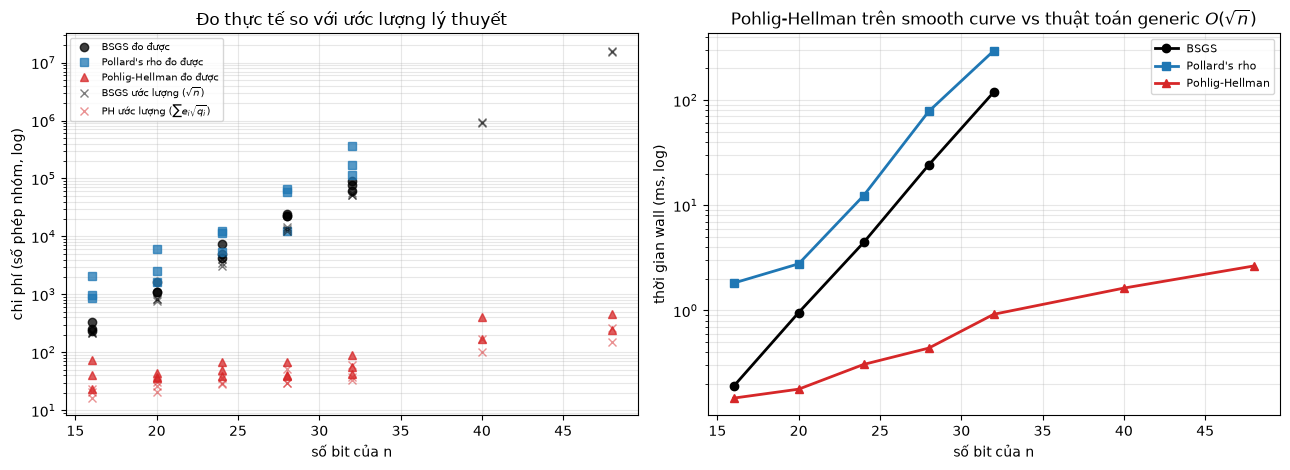

Đã xuất biểu đồ: docs/charts/pohlig_hellman_smooth.png
Tỉ lệ đo_được / ước_lượng (PH):   [4.62, 1.11, 1.76, 1.83, 1.69, 1.15, 2.46, 1.31, 1.34, 1.32, 1.36, 1.32, 1.68, 1.11, 1.51, 1.68, 2.41, 1.74, 1.56]
Tỉ lệ đo_được / ước_lượng (BSGS): [1.53, 1.19, 1.08, 1.41, 1.37, 1.91, 1.83, 1.45, 1.41, 1.81, 1.87, 1.58, 1.73, 1.35, 1.17]


In [19]:
import matplotlib.pyplot as plt

STYLES = {"BSGS": ("k", "o"), "Pollard_Rho": ("tab:blue", "s"), "Pohlig_Hellman": ("tab:red", "^")}


def plot_benchmarks(res_list: List[dict], out_path=None, show: bool = True):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.8))

    for name, (c, m) in STYLES.items():
        pts = [(r["n_bits"], r["algos"][name]["group_ops"]) for r in res_list if name in r["algos"]]
        if pts:
            xs, ys = zip(*pts)
            ax1.semilogy(xs, ys, m, color=c, alpha=.75, linestyle="none", label=f"{ALGO_LABELS[name]} đo được")
    for key, c, label in (("estimated_bsgs_cost", "k", "BSGS ước lượng ($\\sqrt{n}$)"),
                          ("estimated_ph_cost", "tab:red", "PH ước lượng ($\\sum e_i\\sqrt{q_i}$)")):
        ax1.semilogy([r["n_bits"] for r in res_list], [r[key] for r in res_list], "x", color=c, alpha=.5, label=label)
    ax1.set_xlabel("số bit của n"); ax1.set_ylabel("chi phí (số phép nhóm, log)")
    ax1.set_title("Đo thực tế so với ước lượng lý thuyết")
    ax1.grid(alpha=.3, which="both"); ax1.legend(fontsize=7)

    for name, (c, m) in STYLES.items():
        by_bits: Dict[int, List[float]] = {}
        for r in res_list:
            if name in r["algos"]:
                by_bits.setdefault(r["n_bits"], []).append(ms(r["algos"][name]))
        if by_bits:
            xs = sorted(by_bits)
            ax2.plot(xs, [statistics.median(by_bits[x]) for x in xs], marker=m, color=c,
                     linewidth=2, label=ALGO_LABELS[name])
    ax2.set_yscale("log")
    ax2.set_xlabel("số bit của n"); ax2.set_ylabel("thời gian wall (ms, log)")
    ax2.set_title("Pohlig-Hellman trên smooth curve vs thuật toán generic $O(\\sqrt{n})$")
    ax2.grid(alpha=.3, which="both"); ax2.legend(fontsize=8)

    fig.tight_layout()
    if out_path is not None:
        Path(out_path).parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(out_path, dpi=300, bbox_inches="tight")
    if show:
        plt.show()
    return fig


OUT_CHART = CHARTS_DIR / "pohlig_hellman_smooth.png"
plot_benchmarks(results_all, OUT_CHART)
print("Đã xuất biểu đồ:", OUT_CHART.relative_to(ROOT_DIR))

ratio_ph = [round(r["algos"]["Pohlig_Hellman"]["group_ops"] / r["estimated_ph_cost"], 2) for r in results_all]
ratio_bsgs = [round(r["algos"]["BSGS"]["group_ops"] / r["estimated_bsgs_cost"], 2) for r in results_all if "BSGS" in r["algos"]]
print("Tỉ lệ đo_được / ước_lượng (PH):  ", ratio_ph)
print("Tỉ lệ đo_được / ước_lượng (BSGS):", ratio_bsgs)

## Bước 5 – Selftest và giao diện dòng lệnh

Theo đúng convention của các file trước: `selftest()` kiểm tra đúng đắn + nhất quán chi phí (nay có thêm rho và bộ đếm phép
toán), `main(argv)` chạy benchmark hàng loạt rồi ghi CSV, gọi được trực tiếp trong notebook qua `main([...])`.
`--out-d2` chỉ ghi vào `D2_ecdlp_benchmarks.csv` khi được yêu cầu rõ ràng, để lần chạy demo nhỏ không ghi đè bộ dữ liệu đầy đủ.

In [18]:
def selftest() -> bool:
    ok = True
    E = Curve(97, 2, 3)
    P = (3, 6)
    k, R = 1, P
    while R is not None:
        R, k = E.add(R, P), k + 1
    order = k

    print("[1] bsgs_dlp giải đúng trên vài nhóm con nhỏ (tạo tay)")
    for d in (1, 5, order - 1):
        Q = E.mul(d % order, P)
        rec = bsgs_dlp(E, P, Q, order)
        good = rec == d % order
        ok &= good
        print(f"    d={d % order:<4} -> bsgs_dlp={rec} {'OK' if good else 'FAIL'}")

    print("[2] pohlig_hellman khớp bsgs_dlp trên cùng ví dụ")
    fP = factorize(order)
    for d in (2, order // 2, order - 2):
        Q = E.mul(d % order, P)
        rec = pohlig_hellman(E, P, Q, order, fP)
        good = rec == d % order
        ok &= good
        print(f"    d={d % order:<4} -> pohlig_hellman={rec} {'OK' if good else 'FAIL'}")

    print("[3] Trên curve smooth sinh ngẫu nhiên: PH đúng và group_ops <= BSGS toàn nhóm")
    for bits in (16, 20, 24):
        row = generate_curve(bits, mode="smooth", seed=1000 + bits)
        res = benchmark_curve(row, seed=bits, repeat=1)
        al = res["algos"]
        good = all(a["correct"] for a in al.values()) and al["Pohlig_Hellman"]["group_ops"] <= al["BSGS"]["group_ops"]
        ok &= good
        print(f"    n_bits={bits:<3} bsgs_ops={al['BSGS']['group_ops']:<8} rho_ops={al['Pollard_Rho']['group_ops']:<8} "
              f"ph_ops={al['Pohlig_Hellman']['group_ops']:<6} {'OK' if good else 'FAIL'}")

    print("[4] crt_combine tự kiểm (CRT tay vs modulo trực tiếp)")
    import itertools
    good_all = True
    for r2, r3, r5 in itertools.product(range(2), range(3), range(5)):
        x, M = crt_combine([r2, r3, r5], [2, 3, 5])
        good_all &= (x % 2 == r2 and x % 3 == r3 and x % 5 == r5 and M == 30)
    ok &= good_all
    print(f"    {'OK' if good_all else 'FAIL'}")

    print("[5] pollard_rho_dlp khôi phục đúng mọi d trên F_97 và trên curve smooth 16 bit")
    good5 = all(pollard_rho_dlp(E, P, E.mul(d, P), order) == d for d in range(order))
    row = generate_curve(16, mode="smooth", seed=7)
    E16, G16, n16 = Curve.from_row(row), Curve.base_point_from_row(row), int(row["subgroup_n"])
    for d in (1, n16 // 3, n16 - 1):
        good5 &= (pollard_rho_dlp(E16, G16, E16.mul(d, G16), n16) == d)
    ok &= good5
    print(f"    {'OK' if good5 else 'FAIL'}")

    print("[6] track_ecc_ops đếm được phép toán và khôi phục Curve.add/mul sau khi thoát")
    add_before, mul_before = Curve.add, Curve.mul
    with track_ecc_ops() as ops:
        E.mul(5, P)
    good6 = ops.total_ops > 0 and ops.mul_ops == 1 and Curve.add is add_before and Curve.mul is mul_before
    ok &= good6
    print(f"    add={ops.add_ops} double={ops.double_ops} mul={ops.mul_ops} {'OK' if good6 else 'FAIL'}")

    print("SELFTEST:", "PASS" if ok else "FAIL")
    return ok


def main(argv: Optional[List[str]] = None) -> int:
    ap = argparse.ArgumentParser(description="Thực thi Pohlig-Hellman trên smooth curve, so sánh chi phí.")
    ap.add_argument("--selftest", action="store_true")
    ap.add_argument("--min-bits", type=int, default=16)
    ap.add_argument("--max-bits", type=int, default=28)
    ap.add_argument("--step", type=int, default=4)
    ap.add_argument("--bounds", type=int, nargs="+", default=[2**5, 2**8])
    ap.add_argument("--per-combo", type=int, default=1)
    ap.add_argument("--seed", type=int, default=21)
    ap.add_argument("--no-rho", action="store_true", help="bỏ qua Pollard's rho")
    ap.add_argument("--max-generic-bits", type=int, default=32, help="chỉ chạy BSGS/rho khi n <= số bit này")
    ap.add_argument("--out", default=None, help="CSV theo curve (có chi phí ước lượng), vd data/D2_ecdlp_ph_smooth_benchmarks.csv")
    ap.add_argument("--append", action="store_true", help="nối thêm vào --out thay vì ghi đè")
    ap.add_argument("--out-d2", default=None, help="gộp vào D2 dùng chung, vd data/D2_ecdlp_benchmarks.csv")
    args = ap.parse_args(argv)

    if args.selftest:
        return 0 if selftest() else 1

    bit_list = list(range(args.min_bits, args.max_bits + 1, args.step))
    rows, _ = generate_smooth_curve_batch(bit_list, args.bounds, seed=args.seed, per_combo=args.per_combo)
    res_list = [benchmark_curve(r, seed=i, with_rho=not args.no_rho, max_generic_bits=args.max_generic_bits)
                for i, r in enumerate(rows)]
    for res in res_list:
        al = res["algos"]
        extra = f" rho_ops={al['Pollard_Rho']['group_ops']:<8}" if "Pollard_Rho" in al else ""
        sp = f"speedup={res['measured_speedup']:.1f}x" if res["measured_speedup"] is not None else "speedup=n/a"
        print(f"{res['curve_id']} n_bits={res['n_bits']:<3} bsgs_ops={al['BSGS']['group_ops'] if 'BSGS' in al else '-':<8}"
              f"{extra} ph_ops={al['Pohlig_Hellman']['group_ops']:<6} {sp} "
              f"[{'OK' if all(a['correct'] for a in al.values()) else 'FAIL'}]")
    if args.out:
        write_benchmark_csv(res_list, args.out, append=args.append)
        print(f"Đã ghi {sum(len(r['algos']) for r in res_list)} dòng -> {args.out}")
    if args.out_d2:
        n_old, n_new = write_d2_csv(res_list, args.out_d2)
        print(f"Đã gộp {n_old} dòng cũ + {n_new} dòng smooth -> {args.out_d2}")
    return 0 if all_correct(res_list) else 1

In [20]:
# Chạy thử: selftest + demo CLI
selftest()

[1] bsgs_dlp giải đúng trên vài nhóm con nhỏ (tạo tay)
    d=1    -> bsgs_dlp=1 OK
    d=0    -> bsgs_dlp=0 OK
    d=4    -> bsgs_dlp=4 OK
[2] pohlig_hellman khớp bsgs_dlp trên cùng ví dụ
    d=2    -> pohlig_hellman=2 OK
    d=2    -> pohlig_hellman=2 OK
    d=3    -> pohlig_hellman=3 OK
[3] Trên curve smooth sinh ngẫu nhiên: PH đúng và group_ops <= BSGS toàn nhóm
    n_bits=16  bsgs_ops=328      rho_ops=534      ph_ops=17     OK
    n_bits=20  bsgs_ops=1751     rho_ops=5004     ph_ops=99     OK
    n_bits=24  bsgs_ops=5146     rho_ops=10755    ph_ops=62     OK
[4] crt_combine tự kiểm (CRT tay vs modulo trực tiếp)
    OK
[5] pollard_rho_dlp khôi phục đúng mọi d trên F_97 và trên curve smooth 16 bit
    OK
[6] track_ecc_ops đếm được phép toán và khôi phục Curve.add/mul sau khi thoát
    add=1 double=3 mul=1 OK
SELFTEST: PASS


True

In [ ]:
# Demo CLI nhỏ: ghi ra file riêng, không đụng vào bộ dữ liệu đầy đủ ở Bước 4
rc = main(["--min-bits", "16", "--max-bits", "28", "--step", "4",
           "--bounds", "32", "256", "--per-combo", "1", "--seed", "21",
           "--out", str(DATA_DIR / "demo_cli_ph_smooth_benchmarks.csv")])
print("mã trả về:", rc)

## Tổng kết

**Đã hiện thực:**
- `bsgs_dlp`: baby-step giant-step tổng quát, dùng làm cả baseline lẫn subroutine cho PH.
- `pollard_rho_dlp`: Pollard's rho (Floyd, partition 3 phần, xử lý trường hợp order hợp số) làm baseline generic thứ hai,
  bộ nhớ $O(1)$ thay vì $O(\sqrt{n})$ như BSGS.
- `crt_combine`: Định lý số dư Trung Hoa (Garner), ghép các $d \bmod q_i^{e_i}$ thành $d \bmod n$.
- `pohlig_hellman`: thuật toán Pohlig–Hellman đầy đủ, khai thác đúng phân tích thừa số `n_factorization` của D1.
- `benchmark_curve`: đo **thực tế** trên nhiều curve smooth 16–48 bit, cho từng thuật toán: `group_ops`, số phép cộng/nhân đôi/
  nhân vô hướng (`track_ecc_ops`), thời gian wall/CPU, cycles và đỉnh RAM; so với ước lượng lý thuyết
  `estimate_bsgs_cost`/`estimate_ph_cost`.
- `write_benchmark_csv` / `write_d2_csv`: ghi file theo curve (kèm chi phí ước lượng) và gộp vào `data/D2_ecdlp_benchmarks.csv`
  (giữ nguyên các dòng baseline `standard`, thay các dòng `smooth` cũ nên chạy lại không bị nhân đôi).
- `plot_benchmarks`: biểu đồ 2 panel (đo vs lý thuyết; thời gian wall) lưu tại `docs/charts/pohlig_hellman_smooth.png`.

**Kết quả quan sát:** số phép nhóm đo được của Pohlig–Hellman bám khá sát đường ước lượng lý
thuyết $\sum_i e_i\sqrt{q_i}$, trong khi BSGS toàn nhóm và Pollard's rho bám theo $\sqrt n$ — xác nhận thực nghiệm cho lý thuyết đã
trình bày ở notebook trước, và cho thấy mức "vỡ" tăng dần theo số bit khi order vẫn giữ nguyên ngưỡng $B$-smooth. Ở 40–48 bit,
nơi BSGS/rho cần ~$10^6$–$10^7$ phép nhóm, PH vẫn giải trong thời gian ngắn.

**Giới hạn đã biết:**
- `group_ops` chỉ đếm bước baby/giant (BSGS) và bước của dãy (rho) và các phép nhóm trong subroutine của PH, không tính chi phí
  $O(\log n)$ của phép chiếu nhóm con — khớp với đơn vị mà công thức lý thuyết dùng, nhưng là một xấp xỉ. Số liệu
  `track_ecc_ops` (đếm mọi phép cộng/nhân đôi kể cả bên trong nhân vô hướng) bổ sung cho giới hạn này.
- Thời gian/RAM phụ thuộc máy chạy; `cpu_cycles` có thể là ước lượng từ `cpu_time_ns` (cột `cycles_source` ghi rõ nguồn).
- Toy curve ≤ 48 bit; `bsgs_dlp` dùng dict Python nên tốn bộ nhớ $O(\sqrt{\text{order}})$ —
  không mở rộng được lên kích thước mật mã thật (đúng mục đích học thuật của Track A).

---

## Tài liệu tham khảo

Kế thừa danh sách tham khảo của `gen_smooth_curves.ipynb` (Pohlig & Hellman 1978; Wikipedia *Pohlig–Hellman
algorithm*; Galbraith/Auckland ch.13; Pintore, Oxford; NIST SP 800-186; FIPS 186-5; RFC 6090). Riêng phần cài đặt
CRT ở đây theo thuật toán Garner chuẩn (xem thêm: D. Knuth, *The Art of Computer Programming* Vol. 2, mục 4.3.2 —
*The Chinese Remainder Theorem*, một tài liệu kinh điển thường được trích trong các giáo trình số học tính toán). Pollard's rho
theo J. M. Pollard, *Monte Carlo methods for index computation (mod p)*, Math. Comp. 32 (1978).